# Test du VAE

visualisation du vae image vers espace latent image

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from numb_project.constants import VAE_CHECKPOINT_FILE
from numb_project.notebook_utils import *

torch.set_grad_enabled(False)  # notebook d'évaluation uniquement

vae = load_vae(VAE_CHECKPOINT_FILE)
images, labels = mnist_batch(64)

angle=  0°: MSE = 0.00700
angle= 20°: MSE = 0.00401
angle= 40°: MSE = 0.00385
angle= 60°: MSE = 0.00384
angle= 80°: MSE = 0.00396
angle=100°: MSE = 0.00410
angle=120°: MSE = 0.00404
angle=140°: MSE = 0.00406
angle=160°: MSE = 0.00390
angle=180°: MSE = 0.00693
angle=200°: MSE = 0.00374
angle=220°: MSE = 0.00382
angle=240°: MSE = 0.00381
angle=260°: MSE = 0.00391
angle=280°: MSE = 0.00407
angle=300°: MSE = 0.00403
angle=320°: MSE = 0.00401
angle=340°: MSE = 0.00394


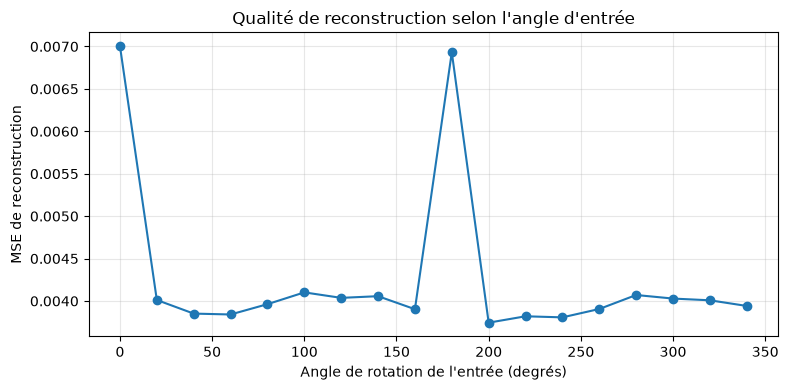

In [2]:
# --- MSE de reconstruction en fonction de l'angle de rotation de l'entrée ---
angles = list(range(0, 360, 20))
mse = []
for angle in angles:
    rotated = rotate_by(images, angle)
    mse.append(F.mse_loss(vae_reconstruct(vae, rotated), rotated).item())
    print(f"angle={angle:>3}°: MSE = {mse[-1]:.5f}")

plt.figure(figsize=(8, 4))
plt.plot(angles, mse, marker="o")
plt.xlabel("Angle de rotation de l'entrée (degrés)")
plt.ylabel("MSE de reconstruction")
plt.title("Qualité de reconstruction selon l'angle d'entrée")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

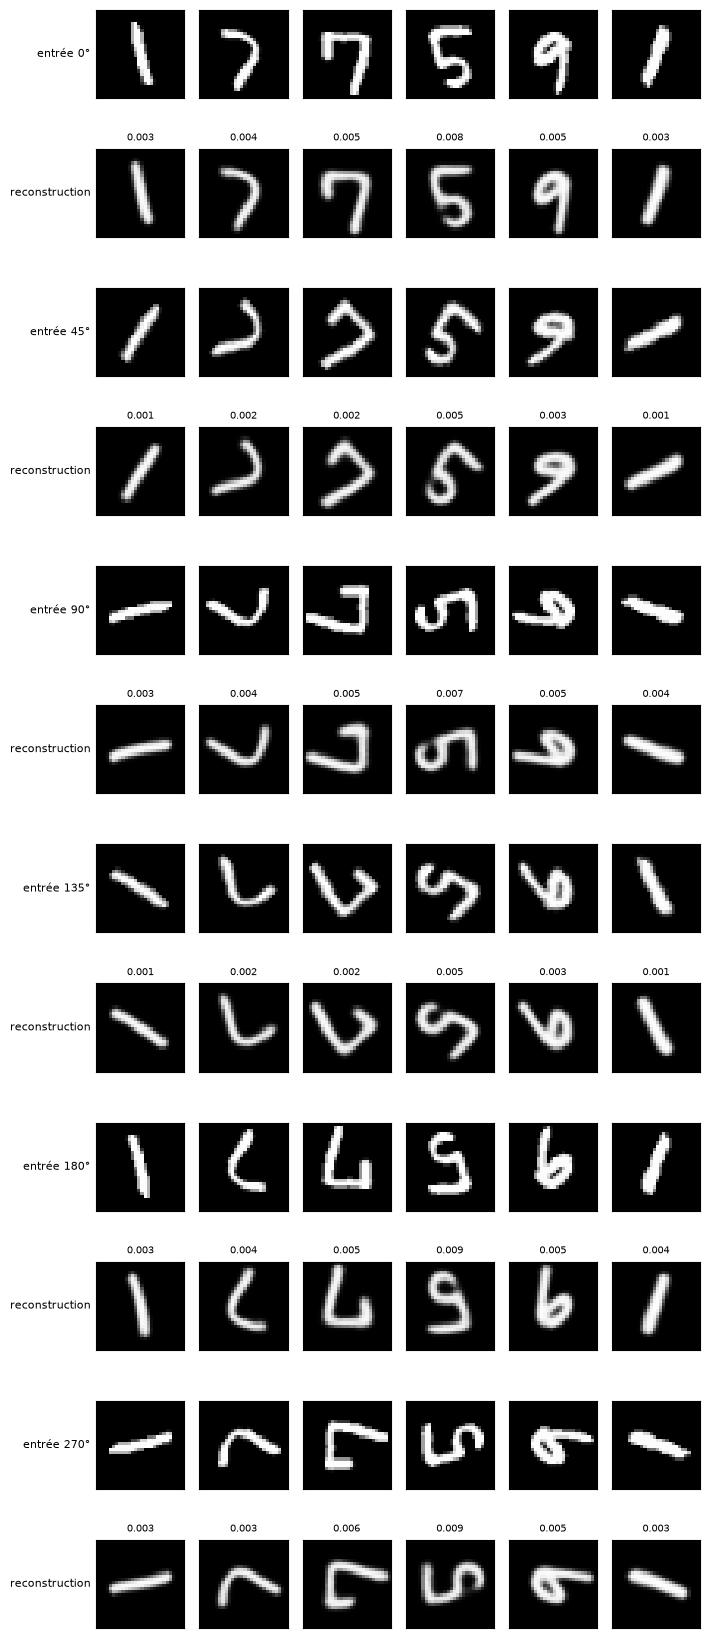

In [3]:
# --- Comparaison qualitative à quelques angles (MSE par image en titre) ---
rows = []
for angle in [0, 45, 90, 135, 180, 270]:
    rotated = rotate_by(images, angle)
    recon = vae_reconstruct(vae, rotated)
    mse_per_image = ((recon - rotated) ** 2).mean(dim=(1, 2, 3))
    rows += [(f"entrée {angle}°", rotated), ("reconstruction", recon, [f"{m:.3f}" for m in mse_per_image.tolist()])]
show_rows(rows, n_show=6)

Dimensions actives : 20 / 20
dim  6: Var[mu]=0.9832  KL=2.586  actif
dim 11: Var[mu]=0.9825  KL=2.030  actif
dim 19: Var[mu]=0.9757  KL=2.051  actif
dim  9: Var[mu]=0.9737  KL=2.598  actif
dim  3: Var[mu]=0.9704  KL=1.615  actif
dim  5: Var[mu]=0.9678  KL=2.597  actif
dim 17: Var[mu]=0.9103  KL=1.669  actif
dim 18: Var[mu]=0.9086  KL=1.655  actif
dim  8: Var[mu]=0.8758  KL=1.183  actif
dim 12: Var[mu]=0.8741  KL=1.210  actif
dim  0: Var[mu]=0.8681  KL=1.166  actif
dim 15: Var[mu]=0.8531  KL=1.215  actif
dim 14: Var[mu]=0.8501  KL=1.050  actif
dim 13: Var[mu]=0.8413  KL=1.140  actif
dim 10: Var[mu]=0.8036  KL=1.007  actif
dim  7: Var[mu]=0.6573  KL=0.643  actif
dim 16: Var[mu]=0.6072  KL=0.559  actif
dim  1: Var[mu]=0.6037  KL=0.533  actif
dim  4: Var[mu]=0.5846  KL=0.506  actif
dim  2: Var[mu]=0.5051  KL=0.415  actif


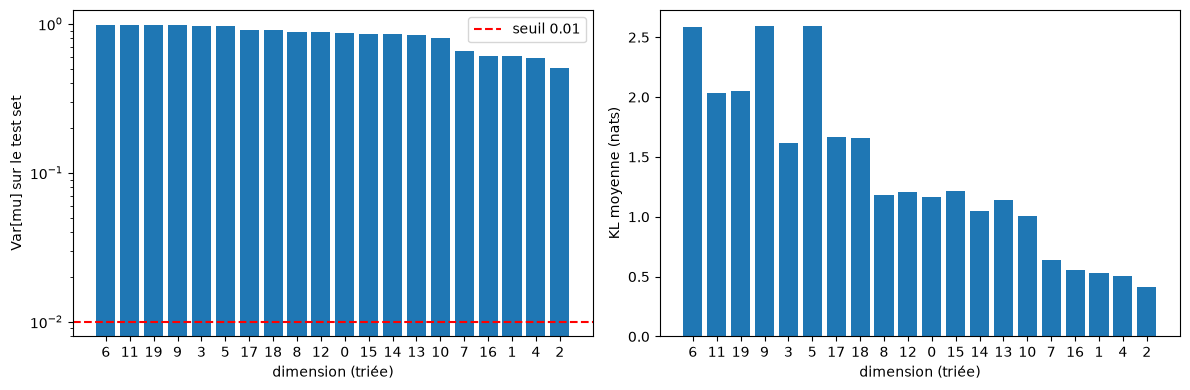

In [4]:
# --- Dimensions actives de l'espace latent ---
# Une dimension est "active" si son mu varie selon l'image (Var_x[mu_d] > 0.01).
# Une dimension morte a un mu ~ constant et un logvar ~ 0 (posterior = prior) :
# elle ne porte aucune information, sa KL moyenne est ~ 0.
all_images, _ = mnist_batch(10000)
mu, logvar = vae.encoder(rotate_images(all_images, random_angles(len(all_images))))

mu_var = mu.var(dim=0).cpu()
kl_per_dim = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).mean(dim=0).cpu()

threshold = 0.01
active = mu_var > threshold
print(f"Dimensions actives : {active.sum().item()} / {len(mu_var)}")
for d in torch.argsort(mu_var, descending=True).tolist():
    print(f"dim {d:>2}: Var[mu]={mu_var[d]:.4f}  KL={kl_per_dim[d]:.3f}  {'actif' if active[d] else 'mort'}")

order = torch.argsort(mu_var, descending=True)
colors = ["C0" if a else "C7" for a in active[order]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(len(mu_var)), mu_var[order], color=colors)
axes[0].axhline(threshold, color="red", linestyle="--", label=f"seuil {threshold}")
axes[0].set_yscale("log")
axes[0].set_ylabel("Var[mu] sur le test set")
axes[0].legend()
axes[1].bar(range(len(kl_per_dim)), kl_per_dim[order], color=colors)
axes[1].set_ylabel("KL moyenne (nats)")
for ax in axes:
    ax.set_xticks(range(len(mu_var)), order.tolist())
    ax.set_xlabel("dimension (triée)")
plt.tight_layout()
plt.show()

In [5]:
# --- Sonde d'angle : l'angle de rotation est-il encodé dans mu ? ---
# On apprend à prédire (cos, sin) de l'angle à partir de mu, sur le train set,
# et on évalue sur le test set :
#  - sonde linéaire : l'angle est-il lisible "directement" dans mu ?
#  - sonde MLP      : l'angle est-il présent, même de façon non linéaire ?
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor

def encode_rotated(train: bool, n_images: int, seed: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    x, x_labels = mnist_batch(n_images, train=train, seed=seed)
    x_angles = random_angles(n_images, seed=seed)
    return vae.encoder(rotate_images(x, x_angles))[0].cpu(), x_angles.cpu(), x_labels.cpu()

mu_train, angle_train, _ = encode_rotated(train=True, n_images=20000, seed=0)
mu_test, angle_test, label_test = encode_rotated(train=False, n_images=10000, seed=1)

probes = {
    "linéaire": Ridge(alpha=1.0),
    "MLP": MLPRegressor(hidden_layer_sizes=(256, 256), max_iter=200, early_stopping=True, random_state=0),
}
pred_angles, errors = {}, {}
for name, probe in probes.items():
    probe.fit(mu_train.numpy(), angle_to_cos_sin(angle_train).numpy())
    pred_angles[name] = cos_sin_to_angle(torch.from_numpy(probe.predict(mu_test.numpy())))
    errors[name] = angle_error(pred_angles[name], angle_test)
    print(f"sonde {name:<8}: erreur moyenne = {errors[name].mean():5.1f}°, médiane = {errors[name].median():5.1f}°, "
          f"< 15° pour {(errors[name] < 15).float().mean():.1%} des images")
print("(hasard : erreur moyenne de 90°)")

# Erreur par chiffre : 0, 1 et 8 sont presque symétriques par rotation de 180°,
# leur angle peut être ambigu même pour un encodeur parfait.
print("\nErreur médiane par chiffre :")
for digit in range(10):
    mask = label_test == digit
    print(f"  {digit}: " + "  ".join(f"{name} {err[mask].median():5.1f}°" for name, err in errors.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes[:2], probes):
    ax.scatter(angle_test, pred_angles[name], s=1, alpha=0.2)
    ax.plot([0, 360], [0, 360], color="red", linewidth=1)
    ax.set_xlabel("angle réel (°)")
    ax.set_ylabel("angle prédit (°)")
    ax.set_title(f"sonde {name} (erreur médiane {errors[name].median():.1f}°)")
width = 0.4
for i, (name, err) in enumerate(errors.items()):
    axes[2].bar(torch.arange(10) + (i - 0.5) * width, [err[label_test == d].median() for d in range(10)], width, label=name)
axes[2].set_xticks(range(10))
axes[2].set_xlabel("chiffre")
axes[2].set_ylabel("erreur médiane (°)")
axes[2].legend()
plt.tight_layout()
plt.show()

OutOfMemoryError: CUDA out of memory. Tried to allocate 480.00 MiB. GPU 0 has a total capacity of 15.73 GiB of which 276.00 MiB is free. Process 3462486 has 312.00 MiB memory in use. Process 3513039 has 714.00 MiB memory in use. Process 1734374 has 274.00 MiB memory in use. Process 1959416 has 272.00 MiB memory in use. Process 1981061 has 272.00 MiB memory in use. Process 1987119 has 226.00 MiB memory in use. Process 1995108 has 272.00 MiB memory in use. Process 2007606 has 12.31 GiB memory in use. Process 2006622 has 272.00 MiB memory in use. Including non-PyTorch memory, this process has 532.00 MiB memory in use. Of the allocated memory 168.53 MiB is allocated by PyTorch, and 217.47 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)